# XAU/USD rates

Declares the USD deposits, the GOFO quotes, and the broker smile, then asks
`sjd.markets.strip` to turn them into pillars. The pillars are saved in
`notebooks/local/xau_usd.db` on the rates label `close`, timestamped 16:00 on the
anchor date. `xau_usd_3y.ipynb` opens that label. A second commodity can use the
same label and the same anchor. A later snapshot is a new datetime.

The quotes below are placeholders. Replace them with the day's market. The
curve conventions stay in the library: USD deposits are Actual/360 on the US
government-bond calendar, GOFO is a simple Actual/360 rate from gold spot, and
the smile is stored as put delta. This notebook needs the `rates` extra
(`pip install QuantLib`).


In [1]:
import logging
from datetime import date, datetime
from pathlib import Path

import matplotlib.pyplot as plt

import sjd
from sjd import markets
from sjd.markets.strip import delta_pillars_from_rr_bf, strip_gofo_to_lease, strip_usd_deposits

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s")
sjd.set_log_level("INFO", dedupe_warnings=True)

anchor = date(2026, 9, 16)
spot = 2_400.0
deposits = {
    "1W": 0.0430,
    "1M": 0.0432,
    "2M": 0.0430,
    "3M": 0.0428,
    "6M": 0.0420,
    "1Y": 0.0405,
    "2Y": 0.0385,
    "3Y": 0.0380,
    "5Y": 0.0390,
}
gofo = {
    "1M": 0.0380,
    "2M": 0.0375,
    "3M": 0.0370,
    "6M": 0.0355,
    "1Y": 0.0335,
    "2Y": 0.0310,
    "3Y": 0.0300,
    "5Y": 0.0305,
}
vols = [
    ("1M", 0.140, -0.010, 0.003, -0.022, 0.012),
    ("3M", 0.145, -0.012, 0.004, -0.026, 0.014),
    ("6M", 0.150, -0.014, 0.005, -0.030, 0.016),
    ("3Y", 0.160, -0.012, 0.006, -0.028, 0.018),
    ("5Y", 0.165, -0.010, 0.007, -0.024, 0.020),
]

xau = markets.quote_spec("XAU", "USD")
usd = strip_usd_deposits(anchor, deposits)
lease = strip_gofo_to_lease(anchor, spot, gofo, usd, xau)
smile = delta_pillars_from_rr_bf(anchor, vols, xau)

assert abs(usd.df(date(2026, 9, 25)) - 0.998926) < 5e-7
one_month = lease.frame().iloc[0]
assert one_month["value_date"] == date(2026, 10, 19)
assert abs(one_month["forward"] - 2_407.8533) < 5e-4
assert abs(one_month["lease"] - 0.0052) < 5e-4

rates_path = Path(sjd.markets.__file__).resolve().parents[2] / "notebooks" / "local" / "xau_usd.db"
loaded = markets.save_market_pillars(
    rates_path,
    label="close",
    as_of=datetime(2026, 9, 16, 16, 0),
    anchor=anchor,
    market="XAU",
    currency="USD",
    spot=spot,
    discount=lease.discount_pillars,
    forward=lease.lease_pillars,
    volatility=smile.rows(),
)
assert abs(loaded.forward.get_forward(date(2026, 10, 19)) - 2_407.8533) < 5e-3
assert loaded.label.name == "close"
assert loaded.label.anchor == anchor
print(f"label {loaded.label.name} at {loaded.label.as_of_text}")
print(f"anchor {anchor}")
print(f"saved {rates_path}")
print(lease.frame().to_string(index=False, float_format=lambda value: f"{value:,.6f}"))


WARNING sjd._core: Anchor has no observation; values are flat through the first observation
INFO sjd.markets.rates: loaded market XAU/USD label close at 2026-09-16T16:00:00 anchor 2026-09-16 roll DETERMINISTIC


label close at 2026-09-16T16:00:00
anchor 2026-09-16
saved E:\Code\sjd\python\notebooks\local\xau_usd.db
tenor value_date     gofo    lease      tau      forward
   1M 2026-10-19 0.038000 0.005183 0.086111 2,407.853333
   2M 2026-11-18 0.037500 0.005465 0.169444 2,415.250000
   3M 2026-12-18 0.037000 0.005746 0.252778 2,422.446667
   6M 2027-03-18 0.035500 0.006386 0.502778 2,442.836667
   1Y 2027-09-20 0.033500 0.006769 1.019444 2,481.963333
   2Y 2028-09-18 0.031000 0.007056 2.030556 2,551.073333
   3Y 2029-09-18 0.030000 0.007330 3.044444 2,619.200000
   5Y 2031-09-18 0.030500 0.007361 5.072222 2,771.286667


## Curves

The left panel is GOFO and the lease rate the database stores. The right panel
is the stored put-delta smile. The anchor row copies the one-month smile so an
expiry before that pillar is still inside the grid.


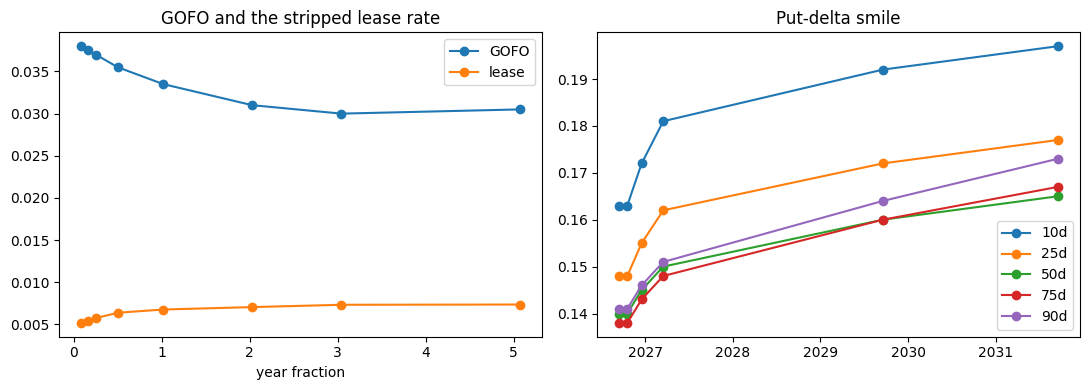

In [2]:
frame = lease.frame()
surface = smile.frame()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(frame["tau"], frame["gofo"], marker="o", label="GOFO")
axes[0].plot(frame["tau"], frame["lease"], marker="o", label="lease")
axes[0].set_title("GOFO and the stripped lease rate")
axes[0].set_xlabel("year fraction")
axes[0].legend()
for delta in smile.deltas:
    axes[1].plot(surface["date"], surface[delta], marker="o", label=f"{delta:.0f}d")
axes[1].set_title("Put-delta smile")
axes[1].legend()
fig.tight_layout()
